# 2. Источники травмы: Source и Secondary Source

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запросы — `SQL/02_sources.sql`.

- **Source** — объект или вещество, непосредственно причинившее травму;
- **Secondary Source** — объект, который способствовал травме (указан не всегда).

Что добавляет Python к SQL-результатам:
- объединение одинаковых названий источников под разными кодами OIICS;
- графики на русском и английском (`figures/ru`, `figures/en`);
- динамика заполнения Secondary Source по годам, связка «раздел Source → раздел Secondary», тяжесть по разделам источников с 95% ДИ и проверкой χ².

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, barh_ranked, wrap, LANGS, TABLES_DIR, MAIN, ACCENT, SERIES
from src.stats import num, cramers_v, share_ci, rank_by_title
from src.labels import norm_title, source_ru, SOURCE_DIVISIONS, SECONDARY_PLACEHOLDERS

set_style()
TABLES_DIR.mkdir(exist_ok=True)

## 2.0. Исходные данные

Одна строка на случай: основной и вторичный источник, код части тела и маска тяжести.

In [2]:
cases = query("""
    SELECT i.id,
           EXTRACT(YEAR FROM i.event_date)::int AS year,
           i.source_code,
           s.title                              AS source,
           i.secondary_source_code              AS sec_code,
           s2.title                             AS secondary,
           i.severity_code
    FROM injuries i
    JOIN source_lookup s       ON s.code  = i.source_code
    LEFT JOIN source_lookup s2 ON s2.code = i.secondary_source_code
""")
cases["sec_code"] = cases["sec_code"].astype("Int64")
cases["src_div"] = cases["source_code"].astype(str).str[0]
cases["src_key"] = cases["source"].map(norm_title)
cases["sec_status"] = np.select(
    [cases["sec_code"].isna(), cases["sec_code"].isin(SECONDARY_PLACEHOLDERS).fillna(False)],
    ["none", "placeholder"], "real")
real = cases["sec_status"] == "real"
cases.loc[real, "sec_div"] = cases.loc[real, "sec_code"].astype(str).str[0]
cases.loc[real, "sec_key"] = cases.loc[real, "secondary"].map(norm_title)
cases["hospitalization"] = (cases["severity_code"] & 4) > 0
cases["amputation"] = (cases["severity_code"] & 2) > 0

N = len(cases)
sec = cases[real]
print(f"Случаев: {num(N)}, из них с реальным вторичным источником: {num(len(sec))}")
cases.head()

Случаев: 105 996, из них с реальным вторичным источником: 43 173


,id,year,source_code,source,sec_code,secondary,severity_code,src_div,src_key,sec_status,sec_div,sec_key,hospitalization,amputation
0,931176,2015,5721,Co-worker,5772,Inmate or detainee in custody,4,5,co worker,real,5,inmate or detainee in custody,True,False
1,930267,2015,7261,"Welding, cutting, and blow torches",<NA>,NaN,4,7,welding cutting and blow torches,none,NaN,NaN,True,False
2,929823,2015,8421,"Semi, tractor-trailer, tanker truck",741,Ladders-fixed,4,8,semi tractor trailer tanker truck,real,7,ladders fixed,True,False
3,929711,2015,8623,Pallet jack-powered,8420,"Truck-motorized freight hauling and utility, u...",4,8,pallet jack powered,real,8,truck motorized freight hauling and utility un...,True,False
4,929642,2015,350,"Metal, woodworking, and special material machi...",<NA>,NaN,4,3,metal woodworking and special material machine...,none,NaN,NaN,True,False


## 2.1. Топ-15 основных источников (Source)

Как и в разделе 1, одинаковые названия под разными кодами объединены (например, «Heat-environmental» 9262 и «Heat environmental» 9273 — один и тот же источник). Красным выделены полы и поверхности, по которым ходят.

In [3]:
src_top = rank_by_title(cases["source"], cases["source_code"])
src_top["source_ru"] = src_top["title"].map(source_ru)
src_top = src_top.reset_index(drop=True)[["title", "source_ru", "codes", "cases", "pct"]]
src_top.index += 1

src_top.head(20).round(2).to_csv(TABLES_DIR / "02_1_top_sources.csv", encoding="utf-8-sig")
src_top.head(20).round(2)

,title,source_ru,codes,cases,pct
1,"Floor, n.e.c.",Пол (прочее),6629,5035,4.75
2,"Forklift, order picker, platform truck-powered","Погрузчик (вилочный, комплектовщик)",8621,4600,4.34
3,Nonclassifiable,Не классифицировано,9999,2780,2.62
4,"Floors, walkways, ground surfaces, unspecified","Полы, проходы, поверхность земли",660,2704,2.55
5,Heat-environmental,Жара (окружающая среда),"9262, 9542",2614,2.47
6,"Machinery, unspecified",Машины (не уточнено),30,1930,1.82
7,Other constructed surface,Прочие искусственные покрытия,6624,1916,1.81
8,Step ladders,Стремянки,"733, 7422",1433,1.35
9,"Ladders, unspecified",Лестницы (не уточнено),740,1357,1.28
10,Pallet jack-powered,Электрическая паллетная тележка,8623,1319,1.24


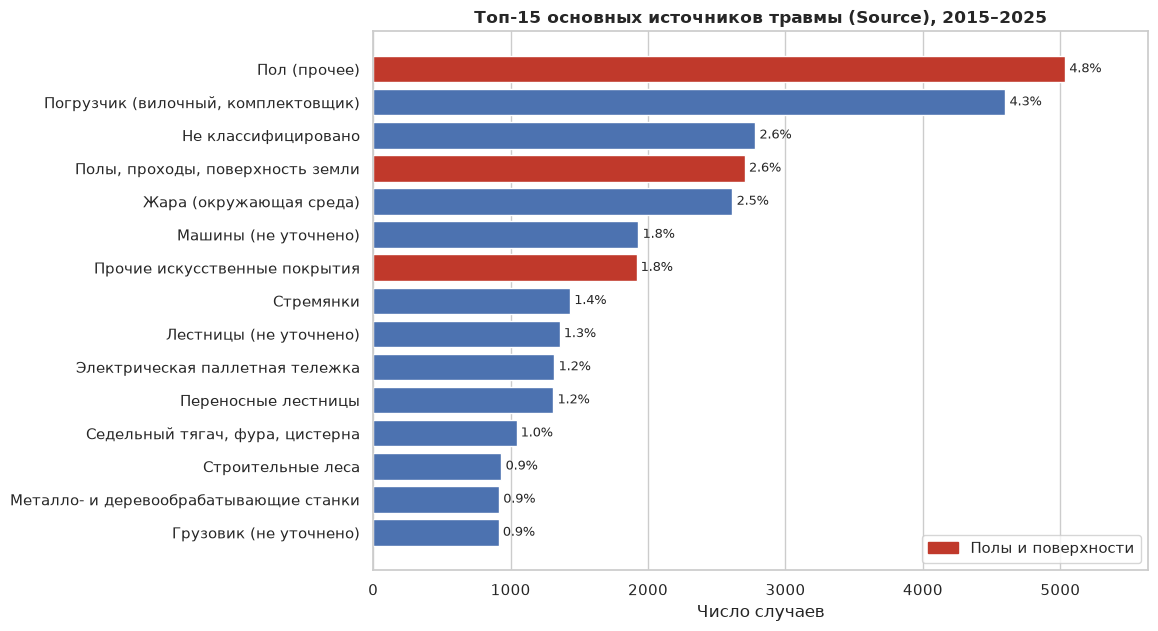

Полы, проходы, поверхности, парковки вместе: 12 330 случаев, 11.6%


In [4]:
t = src_top.head(15)
floor = t["title"].str.contains("floor|ground surface|constructed surface|parking", case=False)

for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    barh_ranked(ax, t["source_ru"] if lang == "ru" else t["title"], t["cases"],
                notes=[f"{p:.1f}%" for p in t["pct"]], color=np.where(floor, ACCENT, MAIN))
    ax.set_title(tr("Топ-15 основных источников травмы (Source), 2015–2025",
                    "Top 15 primary injury sources, 2015–2025", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
              labels=[tr("Полы и поверхности", "Floors and surfaces", lang)], loc="lower right")
    finish(fig, "02_1_top_sources", lang)

surf = src_top[src_top["title"].str.contains("floor|ground surface|constructed surface|parking", case=False)]["cases"].sum()
print(f"Полы, проходы, поверхности, парковки вместе: {num(surf)} случаев, {100 * surf / N:.1f}%")

## 2.2. Топ-15 вторичных источников (Secondary Source)

Доли считаются от случаев, где указан реальный вторичный источник (без пустых значений и заглушек 990/991).

In [5]:
sec_top = rank_by_title(sec["secondary"], sec["sec_code"])
sec_top["secondary_ru"] = sec_top["title"].map(source_ru)
sec_top = sec_top.reset_index(drop=True)[["title", "secondary_ru", "codes", "cases", "pct"]]
sec_top.index += 1

sec_top.head(20).round(2).to_csv(TABLES_DIR / "02_2_top_secondary_sources.csv", encoding="utf-8-sig")
sec_top.head(20).round(2)

,title,secondary_ru,codes,cases,pct
1,"Floors, walkways, ground surfaces, unspecified","Полы, проходы, поверхность земли",660,5282,12.23
2,"Floor, n.e.c.",Пол (прочее),6629,1992,4.61
3,"Ice, sleet, snow","Лёд, мокрый снег, снег",9273,1776,4.11
4,"Forklift, order picker, platform truck-powered","Погрузчик (вилочный, комплектовщик)",8621,1349,3.12
5,"Belts, gloves, neckties, scarves","Ремни, перчатки, галстуки, шарфы",9111,1209,2.8
6,Other constructed surface,Прочие искусственные покрытия,6624,1036,2.4
7,Racks-garment and other,"Стеллажи, вешала",2214,789,1.83
8,"Skids, pallets","Поддоны, паллеты","216, 217",746,1.73
9,Nonclassifiable,Не классифицировано,9999,743,1.72
10,Water,Вода,9521,636,1.47


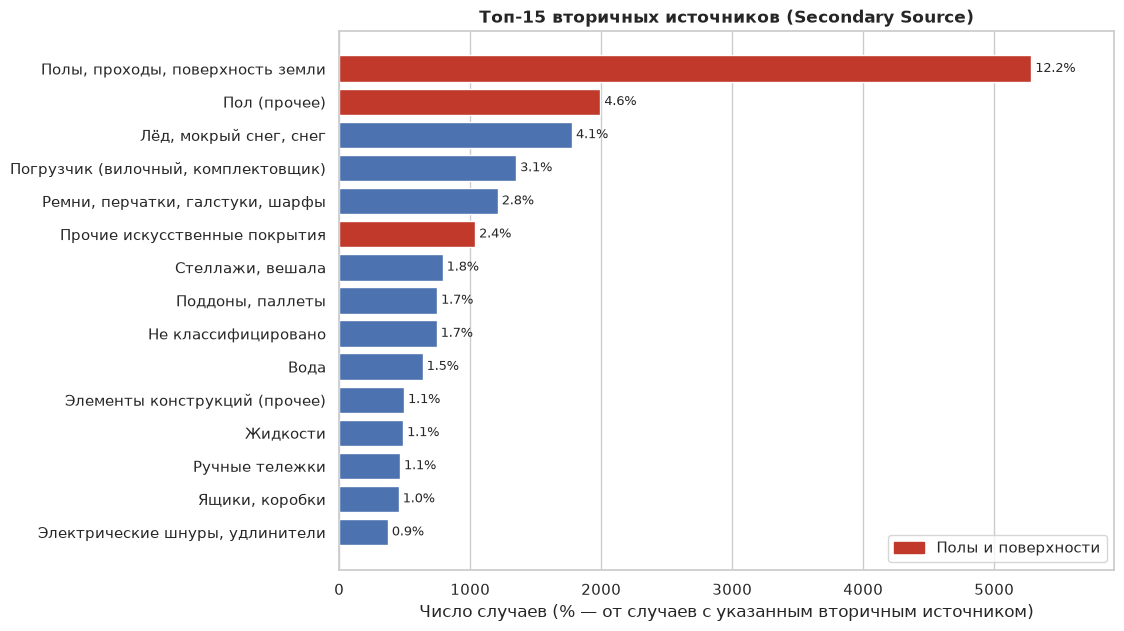

In [6]:
t = sec_top.head(15)
floor = t["title"].str.contains("floor|ground surface|constructed surface|parking", case=False)

for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    barh_ranked(ax, t["secondary_ru"] if lang == "ru" else t["title"], t["cases"],
                notes=[f"{p:.1f}%" for p in t["pct"]], color=np.where(floor, ACCENT, MAIN))
    ax.set_title(tr("Топ-15 вторичных источников (Secondary Source)",
                    "Top 15 secondary sources", lang))
    ax.set_xlabel(tr("Число случаев (% — от случаев с указанным вторичным источником)",
                     "Number of cases (% of cases with a secondary source)", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
              labels=[tr("Полы и поверхности", "Floors and surfaces", lang)], loc="lower right")
    finish(fig, "02_2_top_secondary_sources", lang)

## 2.3. Насколько часто указан вторичный источник

SQL-запрос 2.3 даёт итог за весь период. Здесь добавлена разбивка по годам: она показывает, менялась ли практика заполнения поля. Заглушки 990/991 появляются только с 2024 года — вместе с новой редакцией OIICS.

In [7]:
STATUS = {"real": ("Указан", "Specified"),
          "placeholder": ("Заглушка 990/991", "Placeholder 990/991"),
          "none": ("Не указан (NULL)", "Missing (NULL)")}

status_total = cases["sec_status"].value_counts().reindex(list(STATUS)).rename("cases").to_frame()
status_total["pct"] = (100 * status_total["cases"] / N).round(2)
status_total.index = [STATUS[s][0] for s in status_total.index]
print(status_total, "\n")

status_year = pd.crosstab(cases["year"], cases["sec_status"], normalize="index")[list(STATUS)] * 100
status_year.round(2).to_csv(TABLES_DIR / "02_3_secondary_status_by_year.csv", encoding="utf-8-sig")
status_year.set_axis([STATUS[s][0] for s in STATUS], axis=1).round(1)

                  cases    pct
Указан            43173  40.73
Заглушка 990/991   7442   7.02
Не указан (NULL)  55381  52.25 



,Указан,Заглушка 990/991,Не указан (NULL)
year,,,
2015,25.6,0.0,74.4
2016,27.2,0.0,72.8
2017,26.9,0.0,73.1
2018,38.1,0.0,61.9
2019,42.2,0.0,57.8
2020,43.4,0.0,56.6
2021,43.7,0.0,56.3
2022,46.9,0.0,53.1
2023,44.0,0.0,56.0


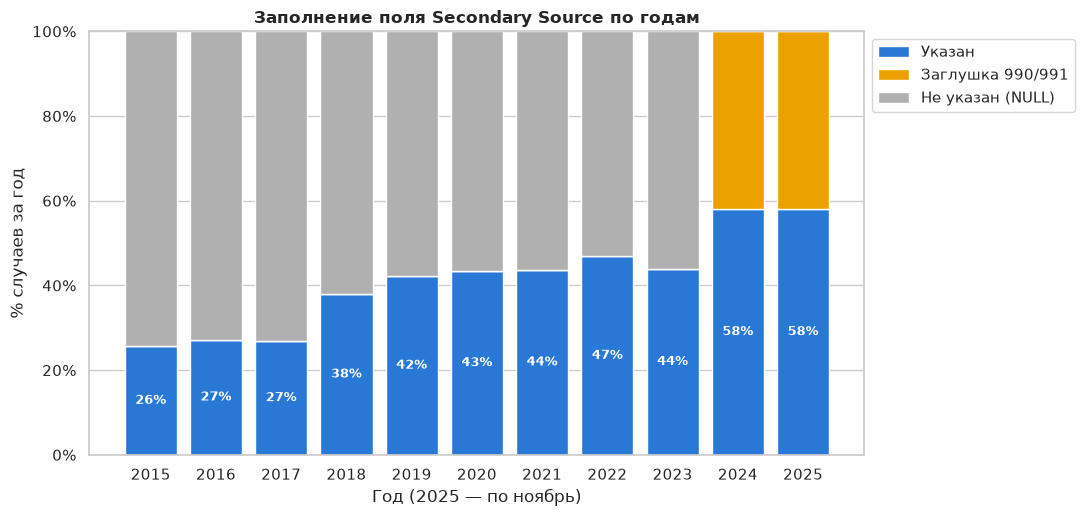

In [8]:
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    bottom = np.zeros(len(status_year))
    for (s, (ru, en)), color in zip(STATUS.items(), [SERIES[0], SERIES[3], "#b0b0b0"]):
        ax.bar(status_year.index, status_year[s], bottom=bottom, color=color,
               edgecolor="white", linewidth=1, label=tr(ru, en, lang))
        bottom += status_year[s].to_numpy()
    for x, v in zip(status_year.index, status_year["real"]):
        ax.text(x, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
    ax.set_title(tr("Заполнение поля Secondary Source по годам",
                    "Secondary Source completeness by year", lang))
    ax.set_xlabel(tr("Год (2025 — по ноябрь)", "Year (2025 — through November)", lang))
    ax.set_ylabel(tr("% случаев за год", "% of cases in year", lang))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xticks(status_year.index)
    ax.set_ylim(0, 100)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    finish(fig, "02_3_secondary_status_by_year", lang)

## 2.4. Разделы источников: Source и Secondary Source рядом

Раздел — первая цифра кода OIICS. Проценты для Source — от всех случаев, для Secondary — от случаев с реальным вторичным источником.

In [9]:
div = pd.DataFrame({
    "as_source": cases["src_div"].value_counts(),
    "as_secondary": sec["sec_div"].value_counts(),
}).fillna(0).astype(int)
div["pct_source"] = 100 * div["as_source"] / div["as_source"].sum()
div["pct_secondary"] = 100 * div["as_secondary"] / div["as_secondary"].sum()
div["name_ru"] = div.index.map(lambda d: SOURCE_DIVISIONS[d][0])
div["name_en"] = div.index.map(lambda d: SOURCE_DIVISIONS[d][1])
div = div.sort_values("as_source", ascending=False)

div.round(2).to_csv(TABLES_DIR / "02_4_source_divisions.csv", encoding="utf-8-sig")
div.round(2)

,as_source,as_secondary,pct_source,pct_secondary,name_ru,name_en
3,26938,4356,25.41,10.09,Машины и механизмы,Machinery
6,22460,12468,21.19,28.88,Конструкции и поверхности,Structures and surfaces
8,15093,3775,14.24,8.74,Транспортные средства,Vehicles
4,12154,5629,11.47,13.04,Детали и материалы,Parts and materials
7,9486,3208,8.95,7.43,"Инструменты, приборы, оборудование","Tools, instruments, equipment"
9,7612,7232,7.18,16.75,Прочие источники,Other sources
2,4732,4862,4.46,11.26,"Тара, мебель, оборудование помещений","Containers, furniture, fixtures"
5,4689,1284,4.42,2.97,"Люди, растения, животные, минералы","Persons, plants, animals, minerals"
1,2832,359,2.67,0.83,Химические вещества,Chemicals


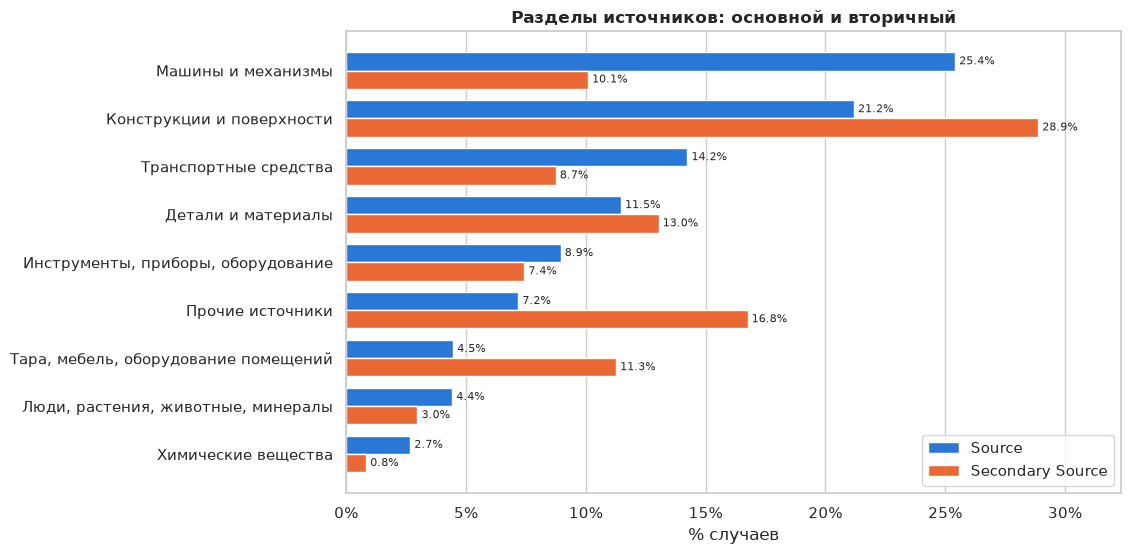

In [10]:
y = np.arange(len(div))[::-1]
h = 0.38
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 6))
    b1 = ax.barh(y + h / 2, div["pct_source"], height=h, color=SERIES[0], label="Source")
    b2 = ax.barh(y - h / 2, div["pct_secondary"], height=h, color=SERIES[1], label="Secondary Source")
    ax.bar_label(b1, labels=[f"{p:.1f}%" for p in div["pct_source"]], padding=3, fontsize=8)
    ax.bar_label(b2, labels=[f"{p:.1f}%" for p in div["pct_secondary"]], padding=3, fontsize=8)
    ax.set_yticks(y, div["name_ru"] if lang == "ru" else div["name_en"])
    ax.set_title(tr("Разделы источников: основной и вторичный",
                    "Source divisions: primary vs secondary", lang))
    ax.set_xlabel(tr("% случаев", "% of cases", lang))
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)
    ax.legend(loc="lower right")
    finish(fig, "02_4_source_divisions", lang)

## 2.5. Общий рейтинг: основной + вторичный источник

Справочник источников общий, поэтому один и тот же объект может быть и причиной травмы, и способствующим фактором. Складываем упоминания в обеих ролях.

In [11]:
both = pd.concat([
    pd.DataFrame({"title": cases["source"], "code": cases["source_code"], "role": "source"}),
    pd.DataFrame({"title": sec["secondary"], "code": sec["sec_code"].astype(int), "role": "secondary"}),
], ignore_index=True)
both["key"] = both["title"].map(norm_title)
mentions = (pd.crosstab(both["key"], both["role"])[["source", "secondary"]]
            .assign(total=lambda d: d.sum(axis=1)).sort_values("total", ascending=False))
names = rank_by_title(both["title"], both["code"])["title"]
mentions.insert(0, "title", names.reindex(mentions.index))
mentions["title_ru"] = mentions["title"].map(source_ru)
mentions["secondary_share"] = (100 * mentions["secondary"] / mentions["total"]).round(1)
mentions = mentions.reset_index(drop=True)
mentions.index += 1

mentions.head(20).to_csv(TABLES_DIR / "02_5_total_mentions.csv", encoding="utf-8-sig")
mentions.head(20)

role,title,source,secondary,total,title_ru,secondary_share
1,"Floors, walkways, ground surfaces, unspecified",2704,5282,7986,"Полы, проходы, поверхность земли",66.1
2,"Floor, n.e.c.",5035,1992,7027,Пол (прочее),28.3
3,"Forklift, order picker, platform truck-powered",4600,1349,5949,"Погрузчик (вилочный, комплектовщик)",22.7
4,Nonclassifiable,2780,743,3523,Не классифицировано,21.1
5,Other constructed surface,1916,1036,2952,Прочие искусственные покрытия,35.1
6,Heat-environmental,2614,39,2653,Жара (окружающая среда),1.5
7,"Machinery, unspecified",1930,234,2164,Машины (не уточнено),10.8
8,"Ice, sleet, snow",12,1776,1788,"Лёд, мокрый снег, снег",99.3
9,Pallet jack-powered,1319,180,1499,Электрическая паллетная тележка,12.0
10,Step ladders,1433,44,1477,Стремянки,3.0


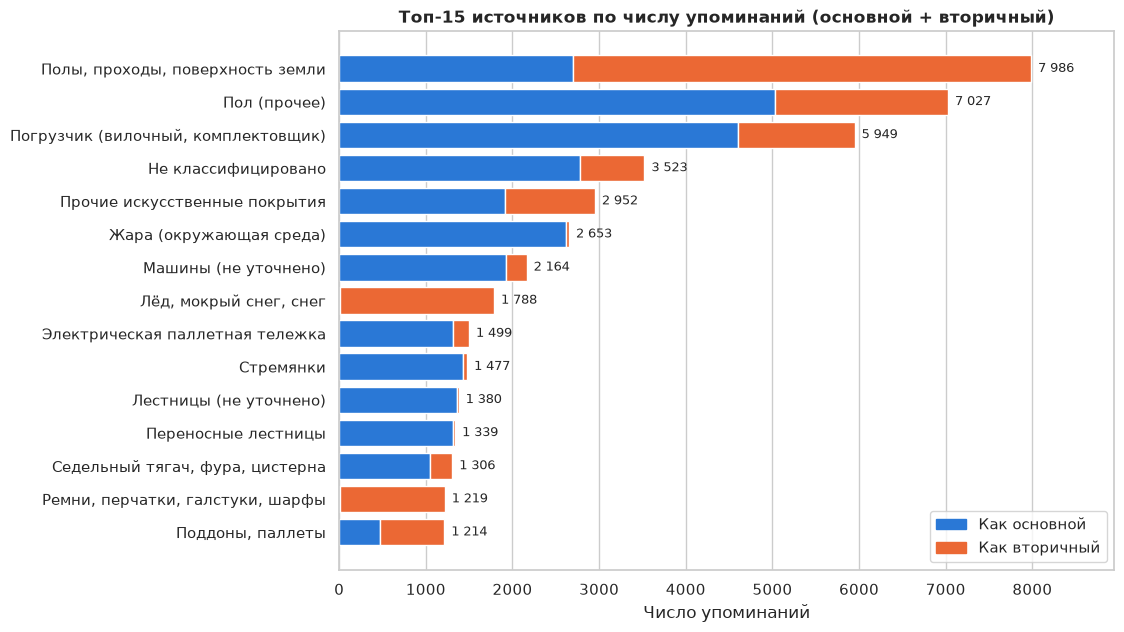

In [12]:
t = mentions.head(15)
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 7))
    labels = t["title_ru"] if lang == "ru" else t["title"]
    barh_ranked(ax, labels, t["source"], color=SERIES[0])
    y = np.arange(len(t))[::-1]
    ax.barh(y, t["secondary"], left=t["source"], color=SERIES[1], edgecolor="white", linewidth=1)
    for yi, tot in zip(y, t["total"]):
        ax.text(tot + 80, yi, num(tot), va="center", fontsize=9)
    ax.set_title(tr("Топ-15 источников по числу упоминаний (основной + вторичный)",
                    "Top 15 sources by total mentions (primary + secondary)", lang))
    ax.set_xlabel(tr("Число упоминаний", "Number of mentions", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in SERIES[:2]],
              labels=[tr("Как основной", "As primary", lang), tr("Как вторичный", "As secondary", lang)],
              loc="lower right")
    finish(fig, "02_5_total_mentions", lang)

## 2.6. Сочетания Source + Secondary Source

Сначала топ-15 конкретных пар (с объединёнными названиями), затем — связь на уровне разделов: из какого раздела обычно вторичный источник при данном основном.

In [13]:
pairs = (sec.groupby(["src_key", "sec_key"]).size().rename("cases")
         .sort_values(ascending=False).reset_index())
src_name = src_top.set_index(src_top["title"].map(norm_title))["title"]
sec_name = sec_top.set_index(sec_top["title"].map(norm_title))["title"]
pairs["source"] = pairs["src_key"].map(src_name)
pairs["secondary"] = pairs["sec_key"].map(sec_name)
pairs["pct_of_with_secondary"] = (100 * pairs["cases"] / len(sec)).round(2)
pairs = pairs.drop(columns=["src_key", "sec_key"])
pairs.index += 1

pairs.head(15).to_csv(TABLES_DIR / "02_6_source_pairs.csv", encoding="utf-8-sig")
pairs.head(15)

,cases,source,secondary,pct_of_with_secondary
1,611,"Floors, walkways, ground surfaces, unspecified","Ice, sleet, snow",1.42
2,374,"Parking lot, unspecified","Ice, sleet, snow",0.87
3,367,"Roofs, unspecified","Floors, walkways, ground surfaces, unspecified",0.85
4,356,"Movable ladders, unspecified","Floors, walkways, ground surfaces, unspecified",0.82
5,346,"Ladders, unspecified","Floors, walkways, ground surfaces, unspecified",0.80
6,343,"Forklift, order picker, platform truck-powered",Racks-garment and other,0.79
7,331,"Forklift, order picker, platform truck-powered","Forklift, order picker, platform truck-powered",0.77
8,331,"Floor, n.e.c.","Liquids, unspecified",0.77
9,324,Step ladders,"Floor, n.e.c.",0.75
10,286,Step ladders,"Floors, walkways, ground surfaces, unspecified",0.66


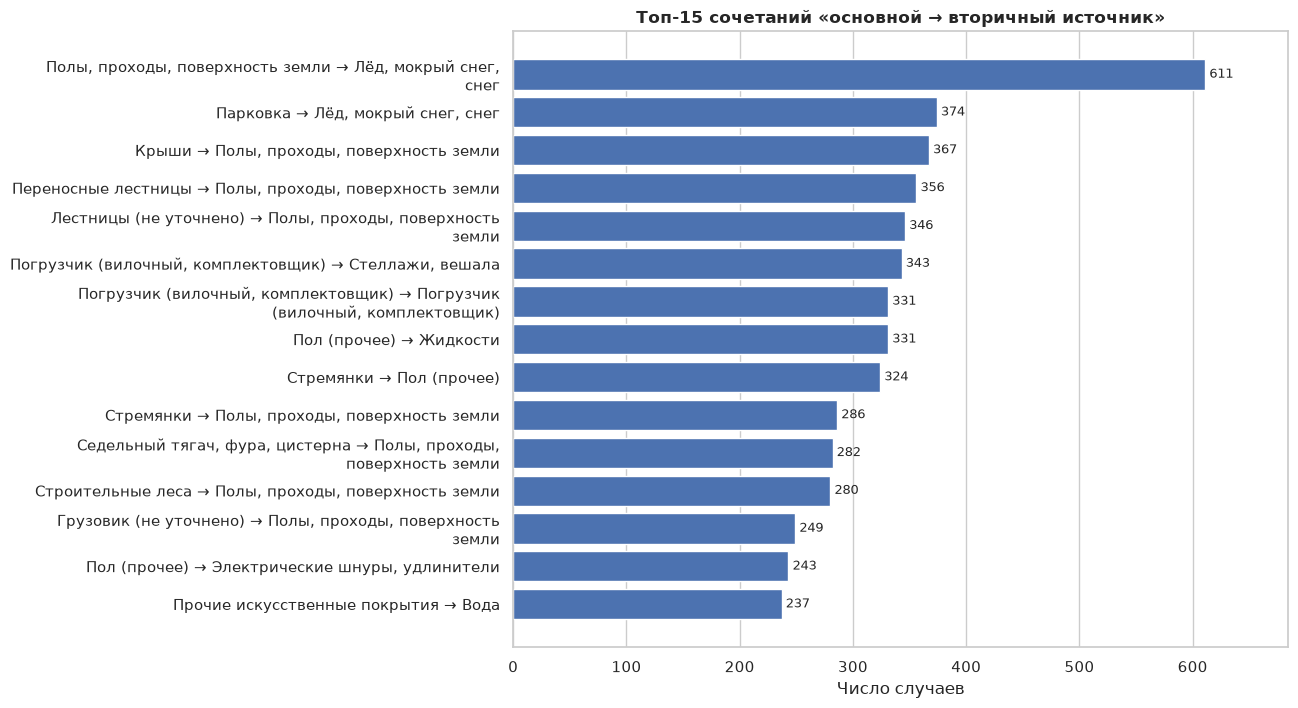

In [14]:
t = pairs.head(15)
for lang in LANGS:
    f = source_ru if lang == "ru" else (lambda s: s)
    labels = [f"{f(a)} → {f(b)}" for a, b in zip(t["source"], t["secondary"])]
    fig, ax = plt.subplots(figsize=(10, 8))
    barh_ranked(ax, labels, t["cases"], notes=[num(c) for c in t["cases"]], width=55)
    ax.set_title(tr("Топ-15 сочетаний «основной → вторичный источник»",
                    "Top 15 primary → secondary source pairs", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    finish(fig, "02_6_source_pairs", lang)

Раздел Source × раздел Secondary: χ² = 23 621, df = 64, p = 0.00e+00, V Крамера = 0.262


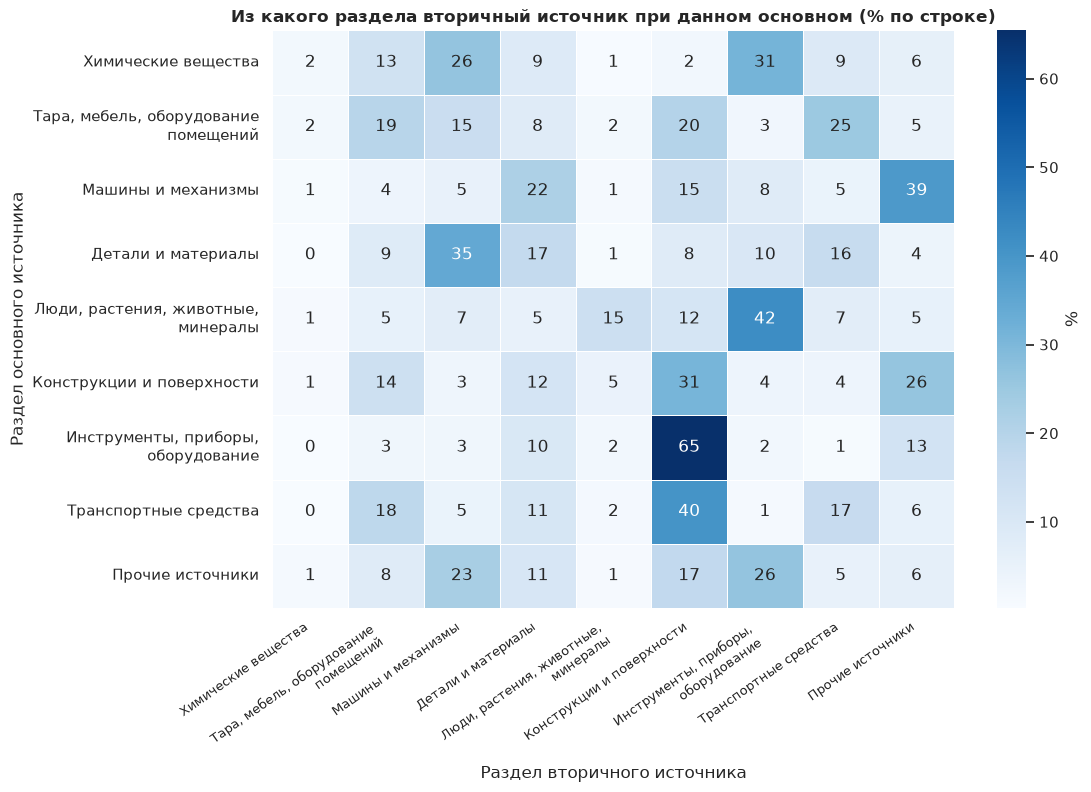

In [15]:
ct_div = pd.crosstab(sec["src_div"], sec["sec_div"])
chi2, p, dof, v, _ = cramers_v(ct_div)
print(f"Раздел Source × раздел Secondary: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")

row_pct = ct_div.div(ct_div.sum(axis=1), axis=0) * 100
row_pct.round(1).to_csv(TABLES_DIR / "02_6_division_pairs_row_pct.csv", encoding="utf-8-sig")

for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(11, 7.5))
    sns.heatmap(row_pct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "%"},
                linewidths=0.5, linecolor="white", ax=ax,
                xticklabels=[wrap(SOURCE_DIVISIONS[d][k], 26) for d in row_pct.columns],
                yticklabels=[wrap(SOURCE_DIVISIONS[d][k], 30) for d in row_pct.index])
    ax.set_title(tr("Из какого раздела вторичный источник при данном основном (% по строке)",
                    "Secondary source division given primary source division (row %)", lang))
    ax.set_xlabel(tr("Раздел вторичного источника", "Secondary source division", lang))
    ax.set_ylabel(tr("Раздел основного источника", "Primary source division", lang))
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
    finish(fig, "02_6_division_pairs_heatmap", lang)

## 2.7. Источники по годам

SQL-запрос 2.7 ставит рядом топ-5 Source и топ-5 Secondary Source каждого года. Здесь то же с объединёнными названиями.

**Смена классификации в 2024 году.** В новой редакции OIICS код 6629 *Floor, n.e.c.* больше не используется — такие случаи кодируются как 6624 *Other constructed surface* (до 2024 года этого кода в данных нет). Также исчезли коды 9999 *Nonclassifiable* и 9262 *Heat-environmental* (теперь 9542 *Heat environmental*). Поэтому рейтинг по точным названиям в 2024–2025 годах несопоставим с предыдущими, а тренды смотрим по укрупнённым группам источников (по ключевым словам в названии).

In [16]:
def top5_by_year(df, key, names):
    g = df.groupby(["year", key]).size().rename("cases").reset_index()
    g["pct_of_year"] = 100 * g["cases"] / g.groupby("year")["cases"].transform("sum")
    g = g.sort_values(["year", "cases"], ascending=[True, False])
    g["place"] = g.groupby("year").cumcount() + 1
    g = g[g["place"] <= 5].copy()
    g["title"] = g[key].map(names)
    return g.set_index(["year", "place"])[["title", "cases", "pct_of_year"]]

by_year = top5_by_year(cases, "src_key", src_name).join(
    top5_by_year(sec, "sec_key", sec_name), lsuffix="_source", rsuffix="_secondary")
by_year.round(2).to_csv(TABLES_DIR / "02_7_top5_by_year.csv", encoding="utf-8-sig")
by_year.round(1)

title_source  cases_source  \
year place                                                                 
2015 1                                       Floor, n.e.c.           518   
     2                                     Nonclassifiable           401   
     3      Forklift, order picker, platform truck-powered           372   
     4      Floors, walkways, ground surfaces, unspecified           290   
     5                                Ladders, unspecified           260   
2016 1                                       Floor, n.e.c.           635   
     2      Forklift, order picker, platform truck-powered           383   
     3                                  Heat-environmental           340   
     4                                     Nonclassifiable           287   
     5                        Movable ladders, unspecified           255   
2017 1                                       Floor, n.e.c.           620   
     2                                     Nonclassifiable           443   
     3      Forklift, order picker, platform truck-powered           416   
     4      Floors, walkways, ground surfaces, unspecified           232   
     5                                  Heat-environmental           230   
2018 1                                       Floor, n.e.c.           626   
     2      Forklift, order picker, platform truck-powered           459   
     3                                     Nonclassifiable           440   
     4                                  Heat-environmental           294   
     5      Floors, walkways, ground surfaces, unspecified           261   
2019 1                                       Floor, n.e.c.           570   
     2      Forklift, order picker, platform truck-powered           452   
     3      Floors, walkways, ground surfaces, unspecified           338   
     4                                  Heat-environmental           315   
     5                                     Nonclassifiable           290   
2020 1                                       Floor, n.e.c.           492   
     2      Forklift, order picker, platform truck-powered           406   
     3      Floors, walkways, ground surfaces, unspecified           274   
     4                                     Nonclassifiable           249   
     5                              Machinery, unspecified           184   
2021 1                                       Floor, n.e.c.           503   
     2      Forklift, order picker, platform truck-powered           443   
     3      Floors, walkways, ground surfaces, unspecified           266   
     4                                     Nonclassifiable           241   
     5                              Machinery, unspecified           220   
2022 1                                       Floor, n.e.c.           543   
     2      Forklift, order picker, platform truck-powered           478   
     3      Floors, walkways, ground surfaces, unspecified           279   
     4                                     Nonclassifiable           225   
     5                                  Heat-environmental           201   
2023 1                                       Floor, n.e.c.           528   
     2      Forklift, order picker, platform truck-powered           460   
     3      Floors, walkways, ground surfaces, unspecified           277   
     4                                  Heat-environmental           248   
     5                                     Nonclassifiable           204   
2024 1                           Other constructed surface           938   
     2      Forklift, order picker, platform truck-powered           382   
     3             Portable ladders and stairs unspecified           297   
     4                                  Heat-environmental           200   
     5                              Machinery, unspecified           169   
2025 1                           Other constructed surface           978   
     2      Forkli

In [17]:
recode = pd.crosstab(cases["year"], cases["source"])[
    ["Floor, n.e.c.", "Other constructed surface", "Nonclassifiable", "Heat-environmental", "Heat environmental"]]
recode

source,"Floor, n.e.c.",Other constructed surface,Nonclassifiable,Heat-environmental,Heat environmental
year,,,,,
2015,518,0,401,215,0
2016,635,0,287,340,0
2017,620,0,443,230,0
2018,626,0,440,294,0
2019,570,0,290,315,0
2020,492,0,249,181,0
2021,503,0,241,173,0
2022,543,0,225,201,0
2023,528,0,204,248,0


In [18]:
# укрупнённые группы источников, устойчивые к смене кодов (ru, en, шаблон по названию)
GROUPS = [
    ("Полы, проходы, поверхности", "Floors, walkways, surfaces",
     r"floor|walkway|ground surface|constructed surface|parking lot"),
    ("Погрузчики, паллетные тележки", "Forklifts, pallet jacks", r"forklift|pallet jack"),
    ("Приставные лестницы, стремянки", "Ladders", r"ladder"),
    ("Жара окружающей среды", "Environmental heat", r"^heat.environmental"),
    ("Конвейеры", "Conveyors", r"conveyor"),
]
for (ru, en, pat), col in zip(GROUPS, ["g_floor", "g_forklift", "g_ladder", "g_heat", "g_conveyor"]):
    cases[col] = cases["source"].str.contains(pat, case=False) & ~cases["source"].str.contains("^fans", case=False)
gcols = ["g_floor", "g_forklift", "g_ladder", "g_heat", "g_conveyor"]

groups_year = cases.groupby("year")[gcols].mean() * 100
groups_year.columns = [g[0] for g in GROUPS]
groups_year.round(2).to_csv(TABLES_DIR / "02_7_source_groups_by_year.csv", encoding="utf-8-sig")
groups_year.round(2)

,"Полы, проходы, поверхности","Погрузчики, паллетные тележки","Приставные лестницы, стремянки",Жара окружающей среды,Конвейеры
year,,,,,
2015,10.82,4.87,5.19,2.19,2.14
2016,10.64,4.92,5.79,3.37,2.08
2017,10.47,5.18,5.70,2.20,1.89
2018,11.16,5.40,5.42,2.64,1.90
2019,12.06,5.52,5.42,2.85,1.77
2020,11.72,6.12,5.83,2.03,2.03
2021,12.27,6.99,5.81,1.99,2.15
2022,12.17,7.04,5.46,2.21,1.83
2023,12.01,6.72,5.51,2.77,1.77


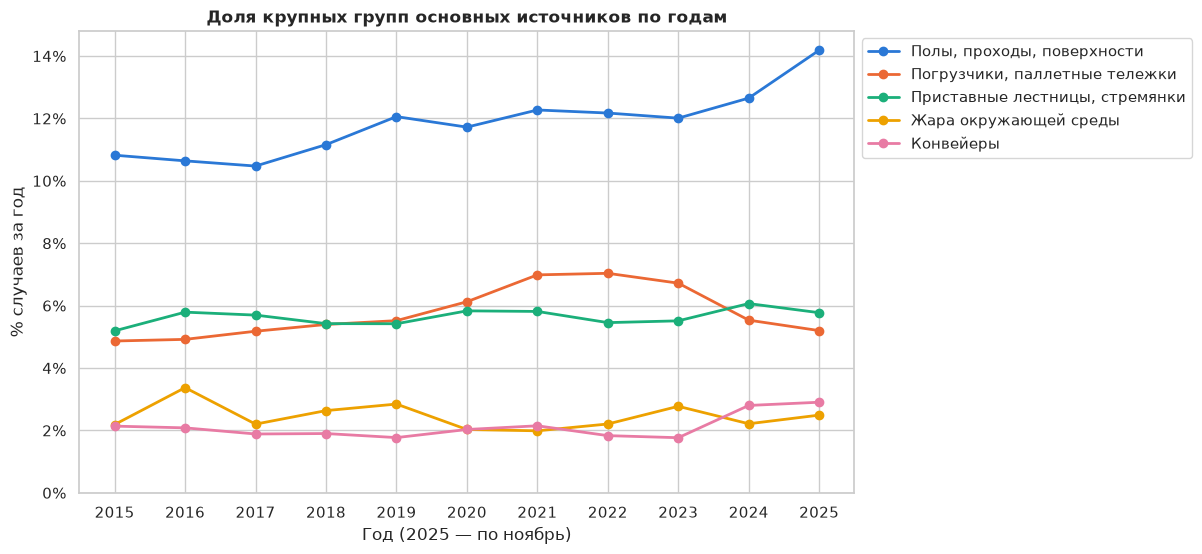

Полы, проходы, поверхности       наклон +0.29 п.п. в год, R² = 0.81, p = 0.000
Погрузчики, паллетные тележки    наклон +0.12 п.п. в год, R² = 0.25, p = 0.116
Приставные лестницы, стремянки   наклон +0.04 п.п. в год, R² = 0.22, p = 0.148
Жара окружающей среды            наклон -0.03 п.п. в год, R² = 0.05, p = 0.510
Конвейеры                        наклон +0.06 п.п. в год, R² = 0.26, p = 0.109


In [19]:
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(10, 6))
    for (ru, en, _), color in zip(GROUPS, SERIES):
        ax.plot(groups_year.index, groups_year[ru], marker="o", color=color, lw=2, label=tr(ru, en, lang))
    ax.set_title(tr("Доля крупных групп основных источников по годам",
                    "Share of major primary source groups by year", lang))
    ax.set_xlabel(tr("Год (2025 — по ноябрь)", "Year (2025 — through November)", lang))
    ax.set_ylabel(tr("% случаев за год", "% of cases in year", lang))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xticks(groups_year.index)
    ax.set_ylim(0, None)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    finish(fig, "02_7_source_groups_by_year", lang)

for ru, *_ in GROUPS:
    lr = stats.linregress(groups_year.index, groups_year[ru])
    print(f"{ru:<32} наклон {lr.slope:+.2f} п.п. в год, R² = {lr.rvalue**2:.2f}, p = {lr.pvalue:.3f}")

## 2.8. Тяжесть последствий по разделам источников

Доля ампутаций и госпитализаций с 95% ДИ Уилсона; связь раздела основного источника с ампутацией — критерий χ² и V Крамера.

In [20]:
rows = []
for d, g in cases.groupby("src_div"):
    for col in ["hospitalization", "amputation"]:
        pct, lo, hi = share_ci(g[col].sum(), len(g))
        rows.append({"division": d, "outcome": col, "cases": len(g), "pct": pct, "ci_low": lo, "ci_high": hi})
sev = pd.DataFrame(rows)
sev["name_ru"] = sev["division"].map(lambda d: SOURCE_DIVISIONS[d][0])
sev["name_en"] = sev["division"].map(lambda d: SOURCE_DIVISIONS[d][1])
sev.round(2).to_csv(TABLES_DIR / "02_8_severity_by_source_division.csv", index=False, encoding="utf-8-sig")

chi2, p, dof, v, _ = cramers_v(pd.crosstab(cases["src_div"], cases["amputation"]))
print(f"Раздел источника × ампутация: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")
sev.pivot(index="name_ru", columns="outcome", values="pct").round(1).sort_values("amputation", ascending=False)

Раздел источника × ампутация: χ² = 27 934, df = 8, p = 0.00e+00, V Крамера = 0.513


outcome,amputation,hospitalization
name_ru,,
Машины и механизмы,62.8,54.7
Детали и материалы,30.3,77.6
"Тара, мебель, оборудование помещений",24.2,81.7
"Инструменты, приборы, оборудование",17.0,86.8
Транспортные средства,15.7,89.8
Прочие источники,9.7,93.4
Конструкции и поверхности,5.9,95.7
"Люди, растения, животные, минералы",3.4,97.7
Химические вещества,0.7,99.8


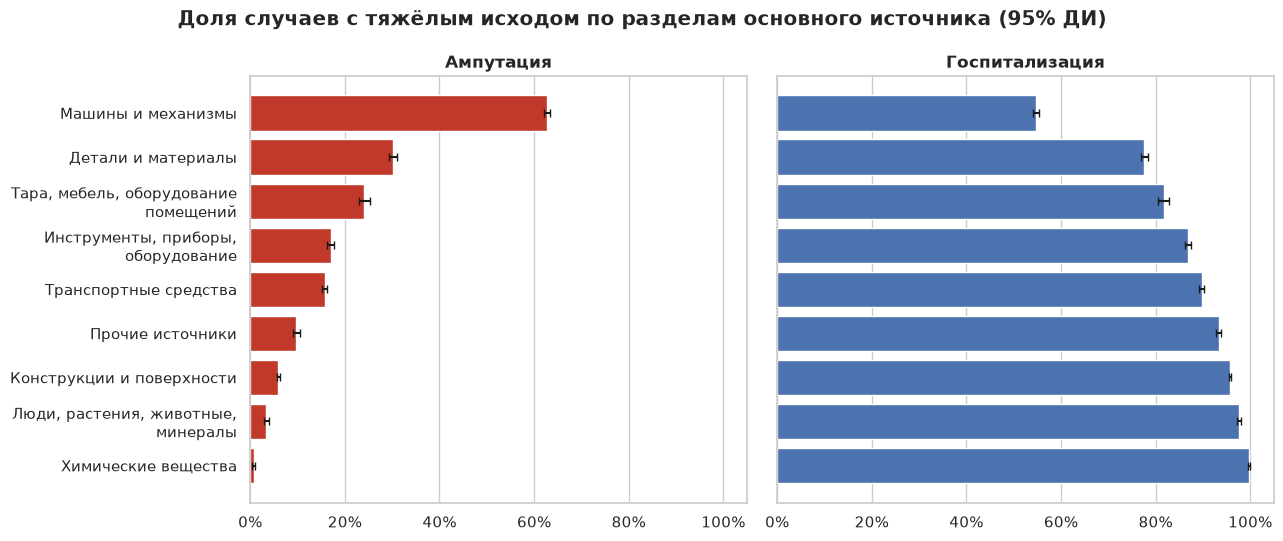

In [21]:
order = (sev[sev["outcome"] == "amputation"].sort_values("pct", ascending=False)["division"].tolist())
for lang in LANGS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
    for ax, col, color in zip(axes, ["amputation", "hospitalization"], [ACCENT, MAIN]):
        s = sev[sev["outcome"] == col].set_index("division").loc[order]
        y = np.arange(len(s))[::-1]
        ax.barh(y, s["pct"], color=color, xerr=[s["pct"] - s["ci_low"], s["ci_high"] - s["pct"]], capsize=3)
        ax.set_yticks(y, [wrap(n, 30) for n in (s["name_ru"] if lang == "ru" else s["name_en"])])
        ax.set_title(tr(*{"hospitalization": ("Госпитализация", "Hospitalization"),
                          "amputation": ("Ампутация", "Amputation")}[col], lang))
        ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
        ax.set_xlim(0, 105)
        ax.grid(axis="y", visible=False)
    fig.suptitle(tr("Доля случаев с тяжёлым исходом по разделам основного источника (95% ДИ)",
                    "Share of cases with severe outcome by primary source division (95% CI)", lang),
                 fontweight="bold")
    fig.tight_layout()
    finish(fig, "02_8_severity_by_source_division", lang)

## Выводы

1. **Главный источник тяжёлых травм — полы и поверхности, по которым ходят.** Полы, проходы, искусственные покрытия и парковки вместе — 11,6% всех случаев как основной источник; в общем рейтинге упоминаний (основной + вторичный) «Полы, проходы, поверхность земли» и «Пол (прочее)» занимают первые два места. Второй по значимости источник — вилочные погрузчики (4,3% случаев, ещё 1,2% — электрические паллетные тележки), дальше — приставные лестницы и стремянки (~5,5% вместе) и жара окружающей среды (2,5%).
2. **Вторичный источник указан только у 40,7% случаев**, у 52% поле пустое, у 7% — заглушки 990/991. Заполненность росла с 26% (2015) до 44–47% (2019–2023), а с 2024 года пустые значения заменены заглушками и реальный источник указан у 58%. Самые частые вторичные источники — полы и поверхности (12,2% + 4,6%), **лёд и снег** (4,1%, почти всегда именно как вторичный — 99% упоминаний) и одежда/перчатки, затянутые в механизм (2,8%).
3. **Роли источников различаются.** Машины и механизмы — 25,4% основных источников, но только 10,1% вторичных; конструкции и поверхности, наоборот, чаще вторичны (28,9%). Типичные пары: падение с лестницы, погрузчика или транспорта на пол/землю (65% вторичных источников при инструментах — это поверхности), поскользнулся на льду на полу или парковке. Связь разделов основного и вторичного источника умеренная (V Крамера = 0,26).
4. **Тяжесть сильно зависит от раздела источника** (χ² = 27 934, df = 8, p < 0,001, V Крамера = 0,51): при травмах от машин и механизмов ампутация в 62,8% случаев, от деталей и материалов — 30%, от конструкций и поверхностей — 5,9%, от химических веществ — 0,7%.
5. **Динамика.** Доля травм от полов и поверхностей растёт на 0,29 п.п. в год (с 10,8% в 2015 до 14,2% в 2025, R² = 0,81, p < 0,001); для погрузчиков, лестниц, жары и конвейеров значимого тренда нет. Методическое замечание: с 2024 года код *Floor, n.e.c.* заменён на *Other constructed surface*, а *Heat-environmental* — на *Heat environmental*, поэтому рейтинги по точным названиям до и после 2024 года несопоставимы — сравнивать нужно укрупнённые группы.